# Домашнее задание к лекции 7
## Обеспечение сетевого трафика предприятия
**Кремезная Марина, БИ2**

**Дисциплина:** Информационная безопасность бизнес-процессов

**Дата:** 17.11.2026

**Тема:** Разработка и совершенствование системы мониторинга сетевого трафика предприятия «ТехноПрофи».

### Цель работы

Разработать и усовершенствовать прототип системы мониторинга сетевого трафика предприятия на языке Python, реализовать обнаружение DDoS-атак, ведение журнала аудита и отправку оповещений, оценить экономическую эффективность внедрения системы и продемонстрировать возможности интеграции с внешними сервисами.

### Задачи работы

1. Реализовать обнаружение потенциальных DDoS-атак на основе анализа количества пакетов в секунду.
2. Организовать ведение журнала аудита событий информационной безопасности.
3. Реализовать отправку оповещений об инцидентах в Telegram и Slack.
4. Рассчитать ROI от внедрения системы мониторинга с учётом стоимости инцидентов, сокращения времени простоя и потерь от утечек данных.
5. Разработать демонстрационные модули интеграции с системой биометрической аутентификации, облачными сервисами AWS и Azure, базами данных угроз MISP и OTX.
6. Провести тестирование разработанных функций и проанализировать полученные результаты.

### Описание предприятия

В качестве объекта исследования рассматривается предприятие «ТехноПрофи» численностью 200 сотрудников. Согласно учебному кейсу, предприятие сталкивается с рисками несанкционированного доступа к финансовым документам, утечек конфиденциальной информации, снижения производительности сети и несоответствия требованиям регуляторов.

Для выполнения работы используется имитация сетевого трафика, позволяющая проверить алгоритмы обнаружения угроз без подключения к реальной корпоративной сети.

# Задание 1. Анализ и улучшение системы мониторинга

## 1.1. Обнаружение DDoS-атак

DDoS-атака (Distributed Denial of Service) представляет собой распределённую атаку, направленную на нарушение доступности сетевых ресурсов за счёт создания чрезмерной нагрузки.

Для обнаружения потенциальных DDoS-атак используется анализ интенсивности сетевого трафика — количества пакетов, поступающих в течение одной секунды (Packets Per Second, PPS).

В рамках учебного прототипа устанавливается пороговое значение 1000 пакетов в секунду. При превышении данного значения система регистрирует подозрительную активность и формирует предупреждение.

Для проверки алгоритма создаётся искусственный сетевой трафик, включающий нормальную активность и аномальный всплеск нагрузки.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Настройки предприятия
COMPANY_NAME = "ТехноПрофи"
DDOS_THRESHOLD = 1000

# Воспроизводимость результатов
np.random.seed(42)

# Генерация учебного трафика за 60 секунд
start_time = datetime.now().replace(microsecond=0)
traffic_data = []

for second in range(60):
    timestamp = start_time + timedelta(seconds=second)

    # Нормальная нагрузка
    packets_count = np.random.randint(20, 81)

    # Искусственный всплеск нагрузки
    if second == 30:
        packets_count = 1500

    traffic_data.append({
        "timestamp": timestamp,
        "packets_per_second": packets_count
    })

# Создание таблицы
traffic_df = pd.DataFrame(traffic_data)

# Обнаружение аномалий
traffic_df["potential_ddos"] = (
    traffic_df["packets_per_second"] > DDOS_THRESHOLD
)

# Результаты
print("СИСТЕМА МОНИТОРИНГА СЕТЕВОГО ТРАФИКА")
print(f"Предприятие: {COMPANY_NAME}")
print(f"Порог обнаружения: {DDOS_THRESHOLD} пакетов/сек.")
print(f"Проанализировано секунд: {len(traffic_df)}")
print(f"Всего пакетов: {traffic_df['packets_per_second'].sum()}")
print(f"Обнаружено аномалий: {traffic_df['potential_ddos'].sum()}")

display(traffic_df[traffic_df["potential_ddos"]])


СИСТЕМА МОНИТОРИНГА СЕТЕВОГО ТРАФИКА
Предприятие: ТехноПрофи
Порог обнаружения: 1000 пакетов/сек.
Проанализировано секунд: 60
Всего пакетов: 4539
Обнаружено аномалий: 1


,timestamp,packets_per_second,potential_ddos
30,2026-11-18 09:04:41,1500,True


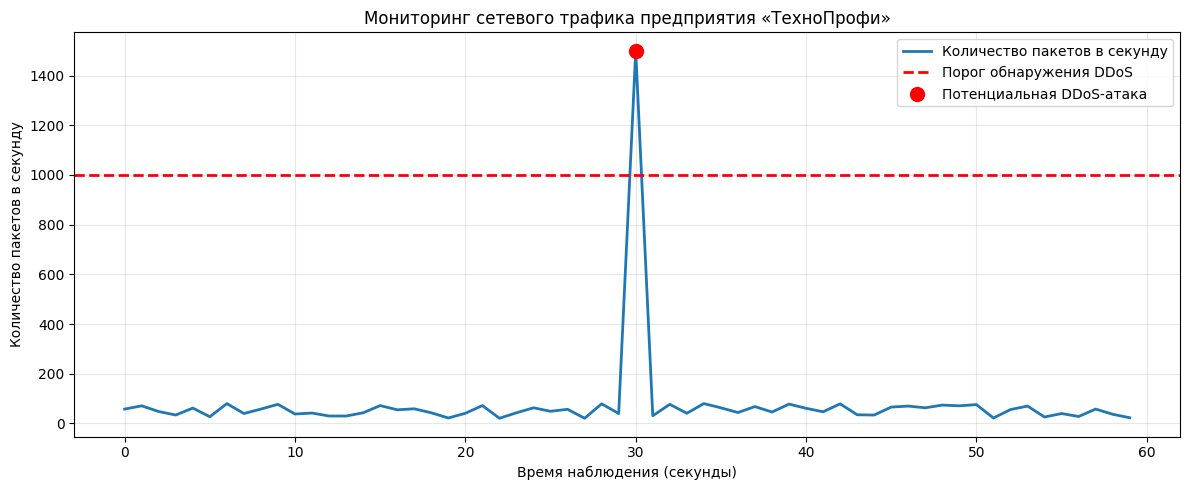

График сохранён: ddos_detection.png


In [2]:

# Визуализация обнаружения DDoS-атаки

plt.figure(figsize=(12, 5))

plt.plot(
    range(len(traffic_df)),
    traffic_df["packets_per_second"],
    label="Количество пакетов в секунду",
    linewidth=2
)

plt.axhline(
    y=DDOS_THRESHOLD,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Порог обнаружения DDoS"
)

# Выделение обнаруженной аномалии
ddos_events = traffic_df[traffic_df["potential_ddos"]]

plt.scatter(
    ddos_events.index,
    ddos_events["packets_per_second"],
    color="red",
    s=100,
    label="Потенциальная DDoS-атака",
    zorder=5
)

plt.title("Мониторинг сетевого трафика предприятия «ТехноПрофи»")
plt.xlabel("Время наблюдения (секунды)")
plt.ylabel("Количество пакетов в секунду")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("ddos_detection.png", dpi=150)
plt.show()

print("График сохранён: ddos_detection.png")


### Результаты обнаружения DDoS-атак

В ходе моделирования был проанализирован сетевой трафик предприятия «ТехноПрофи» за 60 секунд. Общее количество обработанных пакетов составило 4539.

При установленном пороговом значении 1000 пакетов в секунду система обнаружила одну аномалию. На 30-й секунде интенсивность трафика достигла 1500 пакетов в секунду, что превышает установленный порог на 50%.

Построенный график позволяет визуально определить момент возникновения аномальной сетевой активности.

**Вывод:** разработанный алгоритм успешно выявил искусственно созданное превышение допустимой интенсивности трафика. Обнаруженное событие классифицировано как потенциальная DDoS-атака, требующая дополнительной проверки.

## 1.2. Ведение журнала аудита событий безопасности

Журнал аудита предназначен для регистрации и последующего анализа событий информационной безопасности предприятия.

В рамках разработанной системы реализуется автоматическое сохранение обнаруженных аномалий сетевого трафика в журнал формата JSONL.

Для каждого события фиксируются дата и время обнаружения, тип инцидента, уровень критичности, источник события и описание нарушения.

Ведение журнала обеспечивает прослеживаемость событий и способствует выполнению требований по регистрации и анализу событий безопасности, предусмотренных стандартом ISO/IEC 27001.

In [3]:

import json
from datetime import datetime, timezone

# Формирование журнала аудита
audit_events = []

for _, row in traffic_df[traffic_df["potential_ddos"]].iterrows():
    event = {
        "timestamp": row["timestamp"].isoformat(),
        "event_type": "POTENTIAL_DDOS",
        "severity": "HIGH",
        "source": "NetworkTrafficAnalyzer",
        "packets_per_second": int(row["packets_per_second"]),
        "description": "Превышение порога сетевой активности",
        "logged_at": datetime.now(timezone.utc).isoformat()
    }

    audit_events.append(event)

# Сохранение событий в файл JSONL
with open("audit_log.jsonl", "w", encoding="utf-8") as file:
    for event in audit_events:
        file.write(json.dumps(event, ensure_ascii=False) + "\n")

# Вывод результатов
print("ЖУРНАЛ АУДИТА СОБЫТИЙ БЕЗОПАСНОСТИ")
print(f"Зарегистрировано событий: {len(audit_events)}")
print("Файл журнала: audit_log.jsonl")

for event in audit_events:
    print(json.dumps(event, ensure_ascii=False, indent=2))


ЖУРНАЛ АУДИТА СОБЫТИЙ БЕЗОПАСНОСТИ
Зарегистрировано событий: 1
Файл журнала: audit_log.jsonl
{
  "timestamp": "2026-11-18T09:04:41",
  "event_type": "POTENTIAL_DDOS",
  "severity": "HIGH",
  "source": "NetworkTrafficAnalyzer",
  "packets_per_second": 1500,
  "description": "Превышение порога сетевой активности",
  "logged_at": "2026-11-18T09:05:52.989131+00:00"
}


### Результаты ведения журнала аудита

В ходе выполнения программы реализована автоматическая регистрация событий информационной безопасности.

Обнаруженная аномалия сетевого трафика была внесена в журнал аудита с указанием времени возникновения, типа события `POTENTIAL_DDOS`, уровня критичности `HIGH` и интенсивности трафика 1500 пакетов в секунду.

Журнал сохранён в файл `audit_log.jsonl`, что позволяет использовать зарегистрированные события для дальнейшего анализа и расследования инцидентов.

**Вывод:** реализованный механизм обеспечивает регистрацию обнаруженных аномалий и сохранение информации о них в структурированном формате. Для полноценного аудита в производственной системе дополнительно потребуются защита журнала от изменений, контроль доступа и политика хранения записей.

## 1.3. Отправка оповещений в Telegram и Slack

Для оперативного информирования ответственных сотрудников о потенциальных угрозах информационной безопасности разработан модуль отправки уведомлений через Telegram и Slack.

При обнаружении подозрительной сетевой активности система формирует сообщение, содержащее тип инцидента, уровень критичности, время возникновения и описание события.

Для отправки уведомлений используются Telegram Bot API и Slack Incoming Webhooks. В учебной работе предусмотрен демонстрационный режим, позволяющий проверить формирование уведомлений без использования реальных учётных данных.

Применение такого механизма позволяет автоматизировать информирование сотрудников о выявленных угрозах и сократить время реагирования на инциденты.

In [4]:

import os
import json
from urllib import request, error

# Настройки отправки уведомлений
TELEGRAM_BOT_TOKEN = os.getenv("TELEGRAM_BOT_TOKEN")
TELEGRAM_CHAT_ID = os.getenv("TELEGRAM_CHAT_ID")
SLACK_WEBHOOK_URL = os.getenv("SLACK_WEBHOOK_URL")


def send_telegram_notification(message):
    """Отправка уведомления через Telegram Bot API."""

    if not TELEGRAM_BOT_TOKEN or not TELEGRAM_CHAT_ID:
        print("\nTELEGRAM — ДЕМОНСТРАЦИОННЫЙ РЕЖИМ")
        print(message)
        return False

    url = (
        f"https://api.telegram.org/bot"
        f"{TELEGRAM_BOT_TOKEN}/sendMessage"
    )

    payload = json.dumps({
        "chat_id": TELEGRAM_CHAT_ID,
        "text": message
    }).encode("utf-8")

    req = request.Request(
        url,
        data=payload,
        headers={"Content-Type": "application/json"},
        method="POST"
    )

    try:
        with request.urlopen(req, timeout=10) as response:
            result = json.load(response)
            return result.get("ok", False)
    except (error.URLError, ValueError, TimeoutError):
        print("Не удалось отправить уведомление в Telegram")
        return False


def send_slack_notification(message):
    """Отправка уведомления через Slack Webhook."""

    if not SLACK_WEBHOOK_URL:
        print("\nSLACK — ДЕМОНСТРАЦИОННЫЙ РЕЖИМ")
        print(message)
        return False

    payload = json.dumps({
        "text": message
    }).encode("utf-8")

    req = request.Request(
        SLACK_WEBHOOK_URL,
        data=payload,
        headers={"Content-Type": "application/json"},
        method="POST"
    )

    try:
        with request.urlopen(req, timeout=10) as response:
            return response.status == 200
    except (error.URLError, TimeoutError):
        print("Не удалось отправить уведомление в Slack")
        return False


# Формирование оповещений на основе журнала аудита
print("СИСТЕМА ОПОВЕЩЕНИЙ О СОБЫТИЯХ БЕЗОПАСНОСТИ")

for event in audit_events:
    message = (
        "ОПОВЕЩЕНИЕ О БЕЗОПАСНОСТИ\n"
        f"Тип: {event['event_type']}\n"
        f"Критичность: {event['severity']}\n"
        f"Время: {event['timestamp']}\n"
        f"Пакетов в секунду: {event['packets_per_second']}\n"
        f"Описание: {event['description']}"
    )

    telegram_result = send_telegram_notification(message)
    slack_result = send_slack_notification(message)

    print("\nРезультат обработки уведомления:")
    print(f"Telegram отправлено: {telegram_result}")
    print(f"Slack отправлено: {slack_result}")


СИСТЕМА ОПОВЕЩЕНИЙ О СОБЫТИЯХ БЕЗОПАСНОСТИ

TELEGRAM — ДЕМОНСТРАЦИОННЫЙ РЕЖИМ
ОПОВЕЩЕНИЕ О БЕЗОПАСНОСТИ
Тип: POTENTIAL_DDOS
Критичность: HIGH
Время: 2026-11-18T09:04:41
Пакетов в секунду: 1500
Описание: Превышение порога сетевой активности

SLACK — ДЕМОНСТРАЦИОННЫЙ РЕЖИМ
ОПОВЕЩЕНИЕ О БЕЗОПАСНОСТИ
Тип: POTENTIAL_DDOS
Критичность: HIGH
Время: 2026-11-18T09:04:41
Пакетов в секунду: 1500
Описание: Превышение порога сетевой активности

Результат обработки уведомления:
Telegram отправлено: False
Slack отправлено: False


### Результаты реализации системы оповещений

В ходе выполнения работы реализован модуль формирования и отправки уведомлений о событиях информационной безопасности через Telegram и Slack.

На основе зарегистрированного события `POTENTIAL_DDOS` сформировано предупреждение с указанием уровня критичности `HIGH`, времени обнаружения и интенсивности сетевого трафика 1500 пакетов в секунду.

В демонстрационном режиме уведомления выводятся в интерфейсе Google Colab. Программой также предусмотрена возможность реальной отправки сообщений при настройке соответствующих учётных данных.

**Вывод:** разработанный модуль обеспечивает автоматическое формирование предупреждений об обнаруженных аномалиях. Для использования в реальной корпоративной сети необходимо настроить Telegram Bot API или Slack Webhook и проверить фактическую доставку уведомлений.

# Задание 2. Бизнес-кейс: расчёт ROI

## 2.1. Оценка экономической эффективности системы мониторинга

Цель данного задания — оценить экономическую целесообразность внедрения системы мониторинга сетевого трафика на предприятии «ТехноПрофи».

Для оценки используется показатель ROI (Return on Investment), характеризующий возврат инвестиций в систему информационной безопасности.

При расчёте учитываются следующие факторы:

1. Стоимость инцидентов информационной безопасности на основе опубликованных исследований Ponemon Institute.
2. Сокращение финансовых потерь за счёт уменьшения времени простоя информационных систем.
3. Снижение ожидаемых потерь от утечек конфиденциальной информации.
4. Затраты на внедрение и эксплуатацию системы мониторинга.

Расчёт выполняется для периода одного года. Финансовые показатели предприятия являются учебными допущениями, а не фактическими данными компании.

In [5]:

import pandas as pd

# Исходные данные бизнес-кейса
company = "ТехноПрофи"
employees = 200

# Исторический ориентир IBM/Ponemon, 2021
ponemon_breach_cost_usd = 4_240_000

# Учебные финансовые допущения, руб.
implementation_cost = 1_200_000
annual_maintenance = 300_000

# Простой информационных систем
downtime_before = 40
downtime_after = 15
downtime_cost_per_hour = 50_000

# Ожидаемые годовые потери от утечек данных
data_loss_before = 2_000_000
data_loss_after = 800_000

# Ожидаемые годовые потери от других инцидентов
incident_loss_before = 1_500_000
incident_loss_after = 600_000

input_data = pd.DataFrame({
    "Показатель": [
        "Количество сотрудников",
        "Стоимость внедрения, руб.",
        "Годовое обслуживание, руб.",
        "Простой до внедрения, ч/год",
        "Простой после внедрения, ч/год",
        "Стоимость часа простоя, руб.",
        "Потери от утечек до внедрения, руб./год",
        "Потери от утечек после внедрения, руб./год",
        "Другие инциденты до внедрения, руб./год",
        "Другие инциденты после внедрения, руб./год"
    ],
    "Значение": [
        employees,
        implementation_cost,
        annual_maintenance,
        downtime_before,
        downtime_after,
        downtime_cost_per_hour,
        data_loss_before,
        data_loss_after,
        incident_loss_before,
        incident_loss_after
    ]
})

print("ИСХОДНЫЕ ДАННЫЕ ДЛЯ РАСЧЁТА ROI")
print(f"Предприятие: {company}")
print(f"Исторический ориентир IBM/Ponemon: ${ponemon_breach_cost_usd:,}")
print("Все суммы в рублях ниже — учебные допущения.")

display(input_data)


ИСХОДНЫЕ ДАННЫЕ ДЛЯ РАСЧЁТА ROI
Предприятие: ТехноПрофи
Исторический ориентир IBM/Ponemon: $4,240,000
Все суммы в рублях ниже — учебные допущения.


,Показатель,Значение
0,Количество сотрудников,200
1,"Стоимость внедрения, руб.",1200000
2,"Годовое обслуживание, руб.",300000
3,"Простой до внедрения, ч/год",40
4,"Простой после внедрения, ч/год",15
5,"Стоимость часа простоя, руб.",50000
6,"Потери от утечек до внедрения, руб./год",2000000
7,"Потери от утечек после внедрения, руб./год",800000
8,"Другие инциденты до внедрения, руб./год",1500000
9,"Другие инциденты после внедрения, руб./год",600000


### Анализ исходных данных

Для расчёта экономической эффективности внедрения системы мониторинга сетевого трафика предприятия «ТехноПрофи» сформированы исходные финансовые показатели.

Стоимость внедрения системы составляет 1 200 000 рублей, ежегодные расходы на обслуживание — 300 000 рублей. Предполагается, что внедрение системы позволит сократить время простоя информационных систем с 40 до 15 часов в год, а также уменьшить ожидаемые финансовые потери от утечек данных и других инцидентов безопасности.

В качестве исторического ориентира использованы данные исследования IBM/Ponemon Institute о средней стоимости утечки данных. Финансовые показатели предприятия заданы в качестве учебных допущений.

**Вывод:** сформированные исходные данные позволяют рассчитать предполагаемую годовую экономию, возврат инвестиций (ROI) и срок окупаемости системы мониторинга.

## 2.2. Расчёт экономической эффективности внедрения системы

Для оценки экономической эффективности системы мониторинга рассчитываются годовая экономия от сокращения простоев, снижение ожидаемых потерь от инцидентов безопасности, показатель ROI и срок окупаемости инвестиций.

ROI определяется по формуле:

**ROI = (Экономический эффект − Затраты) / Затраты × 100%**

Расчёт выполняется для первого года эксплуатации системы с учётом затрат на внедрение и обслуживание.

In [6]:

# Экономия от сокращения простоев
downtime_savings = (
    downtime_before - downtime_after
) * downtime_cost_per_hour

# Экономия от снижения потерь
data_loss_savings = data_loss_before - data_loss_after
incident_savings = incident_loss_before - incident_loss_after

# Общая годовая экономия
total_savings = (
    downtime_savings
    + data_loss_savings
    + incident_savings
)

# Затраты первого года
total_costs = implementation_cost + annual_maintenance

# Чистый экономический эффект
net_benefit = total_savings - total_costs

# ROI первого года
roi = (net_benefit / total_costs) * 100

# Условный срок окупаемости
annual_net_savings = total_savings - annual_maintenance
payback_months = (
    implementation_cost / annual_net_savings * 12
    if annual_net_savings > 0 else float("inf")
)

roi_results = pd.DataFrame({
    "Показатель": [
        "Экономия от сокращения простоев, руб.",
        "Экономия от снижения потерь при утечках, руб.",
        "Экономия от других инцидентов, руб.",
        "Общая годовая экономия, руб.",
        "Затраты первого года, руб.",
        "Чистый экономический эффект, руб.",
        "ROI первого года, %",
        "Условный срок окупаемости, мес."
    ],
    "Значение": [
        downtime_savings,
        data_loss_savings,
        incident_savings,
        total_savings,
        total_costs,
        net_benefit,
        round(roi, 2),
        round(payback_months, 2)
    ]
})

print("РЕЗУЛЬТАТЫ РАСЧЁТА ROI")
display(roi_results)


РЕЗУЛЬТАТЫ РАСЧЁТА ROI


,Показатель,Значение
0,"Экономия от сокращения простоев, руб.",1250000.00
1,"Экономия от снижения потерь при утечках, руб.",1200000.00
2,"Экономия от других инцидентов, руб.",900000.00
3,"Общая годовая экономия, руб.",3350000.00
4,"Затраты первого года, руб.",1500000.00
5,"Чистый экономический эффект, руб.",1850000.00
6,"ROI первого года, %",123.33
7,"Условный срок окупаемости, мес.",4.72


### Вывод по результатам расчёта

В результате расчётов установлено, что предполагаемая годовая экономия от внедрения системы мониторинга составляет 3 350 000 рублей. При затратах первого года 1 500 000 рублей показатель ROI достигает 123,33%, а условный срок окупаемости составляет 4,72 месяца.

Таким образом, на основе принятых учебных допущений внедрение системы мониторинга сетевого трафика является экономически целесообразным и позволяет снизить ожидаемые финансовые потери предприятия.

## 2.3. Визуализация экономической эффективности

Для наглядного представления результатов расчёта построена столбчатая диаграмма, отражающая основные источники экономии, затраты первого года и чистый экономический эффект от внедрения системы мониторинга сетевого трафика.

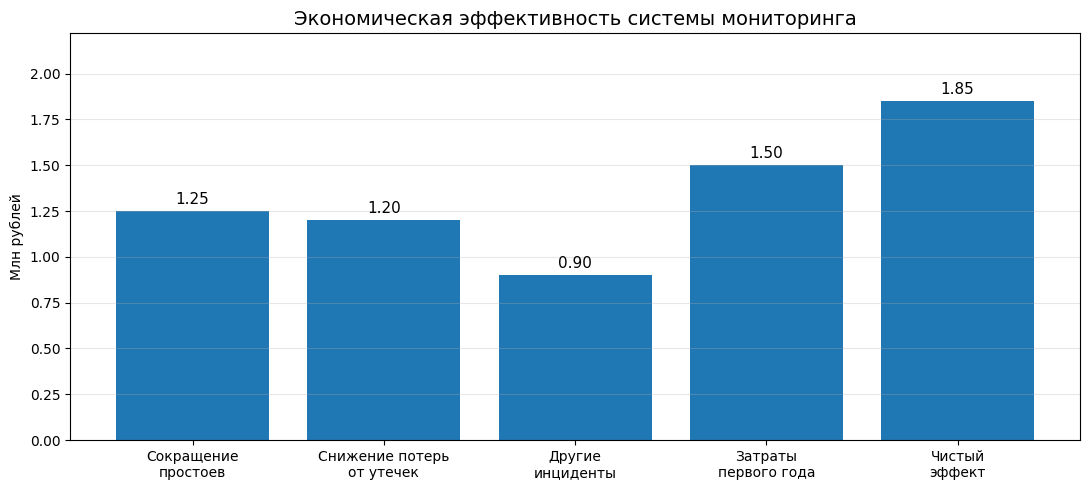

ROI первого года: 123.33%
Условный срок окупаемости: 4.72 мес.


In [7]:

# Визуализация экономической эффективности

import matplotlib.pyplot as plt

categories = [
    "Сокращение\nпростоев",
    "Снижение потерь\nот утечек",
    "Другие\nинциденты",
    "Затраты\nпервого года",
    "Чистый\nэффект"
]

values = [
    downtime_savings / 1_000_000,
    data_loss_savings / 1_000_000,
    incident_savings / 1_000_000,
    total_costs / 1_000_000,
    net_benefit / 1_000_000
]

plt.figure(figsize=(11, 5))

bars = plt.bar(categories, values)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.04,
        f"{value:.2f}",
        ha="center",
        fontsize=11
    )

plt.title(
    "Экономическая эффективность системы мониторинга",
    fontsize=14
)
plt.ylabel("Млн рублей")
plt.ylim(0, max(values) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("roi_analysis.png", dpi=150)
plt.show()

print(f"ROI первого года: {roi:.2f}%")
print(f"Условный срок окупаемости: {payback_months:.2f} мес.")


### Вывод по результатам визуализации

Построенная диаграмма показывает, что наибольшая экономия достигается за счёт сокращения простоев информационных систем и снижения ожидаемых потерь от утечек данных. Чистый экономический эффект первого года превышает затраты на внедрение и обслуживание системы.

Полученные результаты подтверждают экономическую целесообразность проекта в рамках принятого расчётного сценария.

# Задание 3. Интеграция системы мониторинга с дополнительными сервисами

## 3.1. Интеграция с биометрической аутентификацией

Для повышения уровня информационной безопасности предприятия «ТехноПрофи» рассматривается возможность интеграции системы мониторинга с механизмом биометрической аутентификации сотрудников.

Биометрическая аутентификация позволяет подтверждать личность пользователя по уникальным характеристикам, например отпечатку пальца или распознаванию лица.

В учебной модели реализована имитация получения результата биометрической проверки от внешней системы. При неуспешной аутентификации формируется событие безопасности, которое может быть зарегистрировано в журнале аудита.

Данный подход позволяет дополнить мониторинг сетевого трафика контролем попыток несанкционированного доступа.

In [8]:

# Учебная имитация интеграции с биометрической системой

from datetime import datetime, timezone

biometric_attempts = [
    {"user": "employee_001", "verified": True},
    {"user": "employee_002", "verified": False},
    {"user": "employee_003", "verified": True},
    {"user": "unknown_user", "verified": False}
]

biometric_results = []

print("ПРОВЕРКА БИОМЕТРИЧЕСКОЙ АУТЕНТИФИКАЦИИ")

for attempt in biometric_attempts:
    status = "Доступ разрешён" if attempt["verified"] else "Доступ отклонён"

    biometric_results.append({
        "Пользователь": attempt["user"],
        "Результат": status
    })

    if not attempt["verified"]:
        audit_events.append({
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "event_type": "BIOMETRIC_AUTH_FAILURE",
            "severity": "MEDIUM",
            "source": "BiometricAuthSimulator",
            "user": attempt["user"],
            "description": "Неуспешная биометрическая аутентификация"
        })

display(pd.DataFrame(biometric_results))

print(f"Всего проверок: {len(biometric_attempts)}")
print(f"Отклонено попыток: {sum(not a['verified'] for a in biometric_attempts)}")
print(f"Всего событий в памяти журнала аудита: {len(audit_events)}")


ПРОВЕРКА БИОМЕТРИЧЕСКОЙ АУТЕНТИФИКАЦИИ


,Пользователь,Результат
0,employee_001,Доступ разрешён
1,employee_002,Доступ отклонён
2,employee_003,Доступ разрешён
3,unknown_user,Доступ отклонён


Всего проверок: 4
Отклонено попыток: 2
Всего событий в памяти журнала аудита: 3


### Вывод по интеграции с биометрической аутентификацией

В ходе моделирования выполнены четыре проверки биометрической аутентификации, две из которых завершились отказом в доступе. Неуспешные попытки зарегистрированы в списке событий безопасности.

Таким образом, продемонстрирована возможность передачи результатов биометрической проверки в систему мониторинга для последующего анализа и аудита. Реальное подключение биометрического оборудования в рамках учебной модели не выполнялось.

## 3.2. Интеграция с облачными платформами AWS и Azure

Для расширения возможностей мониторинга информационной безопасности предприятия «ТехноПрофи» рассматривается интеграция с облачными платформами Amazon Web Services (AWS) и Microsoft Azure.

В AWS сведения о действиях пользователей и событиях инфраструктуры могут поступать из AWS CloudTrail, а в Azure — из Azure Monitor.

В учебной модели имитируется получение событий безопасности из двух облачных платформ. Система анализирует уровень критичности каждого события и регистрирует подозрительные действия в журнале аудита.

Интеграция позволяет объединить контроль локальной сетевой активности и событий облачной инфраструктуры в единой системе мониторинга.

In [9]:

# Имитация получения событий безопасности из AWS и Azure

from datetime import datetime, timezone

cloud_events = [
    {
        "platform": "AWS",
        "event": "ConsoleLogin",
        "severity": "LOW",
        "description": "Успешный вход в облачную консоль"
    },
    {
        "platform": "AWS",
        "event": "UnauthorizedAccess",
        "severity": "HIGH",
        "description": "Попытка несанкционированного доступа"
    },
    {
        "platform": "Azure",
        "event": "UserLogin",
        "severity": "LOW",
        "description": "Успешная аутентификация пользователя"
    },
    {
        "platform": "Azure",
        "event": "SuspiciousActivity",
        "severity": "HIGH",
        "description": "Обнаружена подозрительная активность"
    }
]

cloud_results = []

print("МОНИТОРИНГ ОБЛАЧНОЙ ИНФРАСТРУКТУРЫ")

for event in cloud_events:
    suspicious = event["severity"] == "HIGH"

    cloud_results.append({
        "Платформа": event["platform"],
        "Событие": event["event"],
        "Критичность": event["severity"],
        "Подозрительное": "Да" if suspicious else "Нет"
    })

    if suspicious:
        audit_events.append({
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "event_type": event["event"],
            "severity": event["severity"],
            "source": event["platform"],
            "description": event["description"]
        })

display(pd.DataFrame(cloud_results))

print(f"Всего облачных событий: {len(cloud_events)}")
print(f"Подозрительных событий: {sum(e['severity'] == 'HIGH' for e in cloud_events)}")
print(f"Всего событий в памяти журнала аудита: {len(audit_events)}")


МОНИТОРИНГ ОБЛАЧНОЙ ИНФРАСТРУКТУРЫ


,Платформа,Событие,Критичность,Подозрительное
0,AWS,ConsoleLogin,LOW,Нет
1,AWS,UnauthorizedAccess,HIGH,Да
2,Azure,UserLogin,LOW,Нет
3,Azure,SuspiciousActivity,HIGH,Да


Всего облачных событий: 4
Подозрительных событий: 2
Всего событий в памяти журнала аудита: 5


### Вывод по интеграции с AWS и Azure

В ходе моделирования обработаны четыре события облачной инфраструктуры AWS и Azure. Два события с высоким уровнем критичности зарегистрированы в списке аудита.

Таким образом, продемонстрирована возможность централизованного анализа событий безопасности из различных облачных платформ. Фактическое подключение к AWS и Azure в рамках учебной работы не выполнялось.

## 3.3. Интеграция с системами анализа угроз MISP и OTX

Для повышения эффективности обнаружения киберугроз рассматривается интеграция системы мониторинга с платформами MISP (Malware Information Sharing Platform) и AlienVault OTX (Open Threat Exchange).

Данные платформы предназначены для обмена информацией об угрозах информационной безопасности и предоставляют индикаторы компрометации, включая подозрительные IP-адреса.

В учебной модели реализована имитация получения индикаторов угроз из MISP и OTX. Система сравнивает проверяемые IP-адреса с известными индикаторами и регистрирует обнаруженные совпадения в журнале аудита.

Такой механизм позволяет дополнить анализ интенсивности сетевого трафика проверкой известных признаков вредоносной активности.

In [10]:

# Учебная имитация интеграции с MISP и OTX

from datetime import datetime, timezone

# Тестовые индикаторы угроз
# Адреса из документационных диапазонов, не реальные угрозы
threat_indicators = {
    "MISP": ["192.0.2.10", "192.0.2.20"],
    "OTX": ["198.51.100.15", "198.51.100.25"]
}

# IP-адреса для проверки
network_ips = [
    "192.0.2.10",
    "203.0.113.5",
    "198.51.100.15",
    "203.0.113.10"
]

threat_results = []

print("ПРОВЕРКА IP-АДРЕСОВ ПО ИНДИКАТОРАМ УГРОЗ")

for ip in network_ips:
    detected_sources = [
        source
        for source, indicators in threat_indicators.items()
        if ip in indicators
    ]

    is_threat = len(detected_sources) > 0

    threat_results.append({
        "IP-адрес": ip,
        "Обнаружена угроза": "Да" if is_threat else "Нет",
        "Источник": ", ".join(detected_sources) if is_threat else "—"
    })

    if is_threat:
        audit_events.append({
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "event_type": "THREAT_INDICATOR_MATCH",
            "severity": "HIGH",
            "source": ", ".join(detected_sources),
            "ip_address": ip,
            "description": "Совпадение с тестовым индикатором угроз"
        })

display(pd.DataFrame(threat_results))

print(f"Проверено IP-адресов: {len(network_ips)}")
print(f"Совпадений с индикаторами: {sum(r['Обнаружена угроза'] == 'Да' for r in threat_results)}")
print(f"Всего событий в памяти журнала аудита: {len(audit_events)}")


ПРОВЕРКА IP-АДРЕСОВ ПО ИНДИКАТОРАМ УГРОЗ


,IP-адрес,Обнаружена угроза,Источник
0,192.0.2.10,Да,MISP
1,203.0.113.5,Нет,—
2,198.51.100.15,Да,OTX
3,203.0.113.10,Нет,—


Проверено IP-адресов: 4
Совпадений с индикаторами: 2
Всего событий в памяти журнала аудита: 7


### Вывод по интеграции с MISP и OTX

В ходе моделирования проверены четыре IP-адреса, два из которых совпали с тестовыми индикаторами угроз MISP и OTX. Выявленные совпадения зарегистрированы в списке событий безопасности.

Таким образом, продемонстрирована возможность использования внешних источников информации об угрозах для дополнительного анализа сетевой активности. Реальные запросы к MISP и OTX в рамках учебной модели не выполнялись.

## 3.4. Формирование итогового журнала аудита

После выполнения всех этапов мониторинга производится сохранение зарегистрированных событий безопасности в единый журнал аудита.

Журнал объединяет результаты обнаружения потенциальной DDoS-атаки, неуспешных попыток биометрической аутентификации, подозрительных событий облачной инфраструктуры и совпадений с тестовыми индикаторами угроз.

Сохранение событий в формате JSON Lines позволяет использовать журнал для последующего анализа и обработки средствами информационной безопасности.

In [11]:

# Сохранение итогового журнала аудита

import json
import pandas as pd

audit_file = "audit_log.jsonl"

with open(audit_file, "w", encoding="utf-8") as file:
    for event in audit_events:
        file.write(
            json.dumps(event, ensure_ascii=False) + "\n"
        )

# Проверка сохранённых событий
with open(audit_file, "r", encoding="utf-8") as file:
    saved_events = [
        json.loads(line)
        for line in file
        if line.strip()
    ]

audit_summary = pd.DataFrame(saved_events)

print("ИТОГОВЫЙ ЖУРНАЛ АУДИТА")
print(f"Файл: {audit_file}")
print(f"Сохранено событий: {len(saved_events)}")

display(
    audit_summary[
        ["event_type", "severity", "source"]
    ].fillna("—")
)

print("\nКоличество событий по типам:")
print(audit_summary["event_type"].value_counts())


ИТОГОВЫЙ ЖУРНАЛ АУДИТА
Файл: audit_log.jsonl
Сохранено событий: 7


,event_type,severity,source
0,POTENTIAL_DDOS,HIGH,NetworkTrafficAnalyzer
1,BIOMETRIC_AUTH_FAILURE,MEDIUM,BiometricAuthSimulator
2,BIOMETRIC_AUTH_FAILURE,MEDIUM,BiometricAuthSimulator
3,UnauthorizedAccess,HIGH,AWS
4,SuspiciousActivity,HIGH,Azure
5,THREAT_INDICATOR_MATCH,HIGH,MISP
6,THREAT_INDICATOR_MATCH,HIGH,OTX



Количество событий по типам:
event_type
BIOMETRIC_AUTH_FAILURE    2
THREAT_INDICATOR_MATCH    2
POTENTIAL_DDOS            1
UnauthorizedAccess        1
SuspiciousActivity        1
Name: count, dtype: int64


### Вывод по формированию журнала аудита

В результате выполнения работы в единый журнал аудита сохранены семь событий информационной безопасности, выявленных при моделировании сетевого мониторинга и дополнительных интеграций.

Журнал содержит сведения о типах событий, уровне критичности и источниках обнаружения. Полученные данные могут использоваться для последующего анализа инцидентов и подготовки отчётности.

# Заключение

В ходе выполнения практической работы была разработана и исследована учебная система мониторинга сетевого трафика предприятия «ТехноПрофи».

Реализовано обнаружение потенциальных DDoS-атак по количеству пакетов в секунду, ведение журнала аудита и формирование уведомлений для Telegram и Slack.

Проведена оценка экономической эффективности внедрения системы. На основе учебных допущений рассчитан ROI первого года, составивший 123,33%, и условный срок окупаемости — 4,72 месяца.

Дополнительно смоделированы интеграции с биометрической аутентификацией, облачными платформами AWS и Azure, а также источниками информации об угрозах MISP и OTX.

В результате продемонстрированы возможности комплексного мониторинга событий информационной безопасности и централизованного ведения журнала аудита. Реальные подключения к внешним сервисам в рамках учебной модели не выполнялись.

**Цель практической работы достигнута.**